# 04 — Development-Data Corrections to Notebooks 01 and 02 (IEEE-CIS Fraud Detection)

**Project:** Fraud Detection Under Limited Review Capacity: A Temporally Validated Study of Tree-Based and Neural Models and Decision Policies
**Programme / module:** MSc Data Science and Its Applications, University of Greenwich — COMP1885 Individual Project
**GitHub Issue:** [#59](https://github.com/chathuranga-sudusinghe/fraud-detection-review-capacity/issues/59)
**Notebook status:** data-understanding evidence. No model is trained, no file is written, and no Test-period label is read. All outputs are aggregates.

## Purpose

A read-only re-check of the saved data-understanding notebooks found four computation findings. Notebooks 01–03 are saved evidence and stay unchanged; notebook 01 cannot be re-run while the Test period is sealed, because its loader reads the full label column. This notebook recomputes the affected quantities on development data, **once with the method of notebook 01 or 02 and once with the corrected method**, so that every difference is visible:

1. **Oracle recall and precision ceilings and maximum lift** (notebook 01 §6) for every capacity scenario of notebook 01, on Validation 2.
2. **Population Stability Index (PSI)** (notebook 01 §14.1) with a separate missing-value bin for categorical columns.
3. **Missingness blocks of the `V1`–`V339` columns** (notebook 01 §8): groups by number of missing Train rows versus groups by identical missing-row pattern.
4. **Duplicate column names** (notebook 02 §2.2) read from the raw header line.

Reproducing the saved notebook 01 values with the notebook 01 method first confirms that the data and the replication match; the corrected values are then compared with them.

## Test-sealing rule

The labelled file `train_transaction.csv` contains all 182 relative days, including the sealed Test period (relative days 155–182, [DR-001](../docs/decisions/DR-001-temporal-split-strategy.md)). A relative day is `TransactionDT` (time offset in seconds from an undisclosed reference point) divided by 86,400 seconds and rounded down.

- The header line and the key columns `TransactionID` and `TransactionDT` (no label, no feature value) are read for all rows, to assert the boundary.
- Every statistic uses **development rows only** (relative days 1–154: Train, Validation 1 and Validation 2). Rows are sorted by time, so only the first 511,998 transaction rows are read, and the day-154 boundary is asserted, as in [notebook 03](03_merged_dataset_inspection.ipynb).

Evidence tags: **[D]** observed dataset evidence; **[I]** inference or recommendation.

## 1. Setup

In [1]:
import csv
import hashlib
import platform
import sys
from collections import Counter
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data" / "raw"
TX_PATH = RAW / "train_transaction.csv"
ID_PATH = RAW / "train_identity.csv"
FEATURES_PATH = ROOT / "config" / "features.yaml"

KEY, TARGET, TIME = "TransactionID", "isFraud", "TransactionDT"
SECONDS_PER_DAY = 86_400

# Chronological partitions by relative day and their row counts (DR-001).
PARTITIONS = {"Train": (1, 105), "V1": (106, 126), "V2": (127, 154), "Test": (155, 182)}
DEV_PARTITIONS = ["Train", "V1", "V2"]
EXPECTED_PARTITION_ROWS = {"Train": 368_632, "V1": 65_544, "V2": 77_822, "Test": 78_542}
DEV_ROWS = sum(EXPECTED_PARTITION_ROWS[p] for p in DEV_PARTITIONS)   # 511,998
TOTAL_ROWS = DEV_ROWS + EXPECTED_PARTITION_ROWS["Test"]              # 590,540
LAST_DEV_DAY = PARTITIONS["V2"][1]                                   # 154

# File integrity anchors recorded in notebook 01, section 2.1.
EXPECTED_SHA256 = {
    "train_transaction.csv": "3a5c83ab6b3cc13dcabe5ffa9f522307fd5f7f7b6e6f6a60c32284ca6283d642",
    "train_identity.csv": "b63c725d8377be90a995268d97f347c17d456b95db45807adcf9f59cd603c37c",
}


def relative_day(transaction_dt):
    """Relative day = floor(TransactionDT / 86,400); no calendar date is inferred."""
    return transaction_dt // SECONDS_PER_DAY


def partition_of(day):
    for name, (first, last) in PARTITIONS.items():
        if first <= day <= last:
            return name
    raise ValueError(f"Relative day {day} lies outside DR-001 partitions")


def sha256(path, chunk=1 << 22):
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while block := handle.read(chunk):
            digest.update(block)
    return digest.hexdigest()


print("Python", sys.version.split()[0], "|", platform.platform())
for module in (pd, np, matplotlib, yaml):
    print(f"{module.__name__:<11}{module.__version__}")
print("Repository root:", ROOT)

Python 3.12.3 | Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
pandas     3.0.6
numpy      2.5.3
matplotlib 3.11.2
yaml       6.0.3
Repository root: /home/chathuranga/projects/fraud-detection-review-capacity


## 2. File integrity and raw header names (corrects notebook 02 §2.2)

Notebook 02 checked duplicate column names on the names returned by `pandas.read_csv(..., nrows=0)`. pandas renames a repeated header (for example `a, a` becomes `a, a.1`), so that check could not fail. Here the **raw header line** of each file is read with the `csv` module, so a repeated name would be counted as a duplicate.

In [2]:
integrity = pd.DataFrame([
    {"file": p.name, "sha256 matches notebook 01": sha256(p) == EXPECTED_SHA256[p.name]}
    for p in (TX_PATH, ID_PATH)
])
assert integrity["sha256 matches notebook 01"].all(), "Raw file differs from the file audited in notebook 01"

header_rows = []
for path in (TX_PATH, ID_PATH):
    with open(path, newline="") as handle:
        names = next(csv.reader(handle))
    repeated = {name: n for name, n in Counter(names).items() if n > 1}
    header_rows.append({"file": path.name, "header names": len(names),
                        "distinct names": len(set(names)), "repeated names": repeated or "none"})
headers = pd.DataFrame(header_rows)
display(integrity)
headers

,file,sha256 matches notebook 01
0,train_transaction.csv,True
1,train_identity.csv,True


,file,header names,distinct names,repeated names
0,train_transaction.csv,394,394,none
1,train_identity.csv,41,41,none


## 3. Development data (Test sealed)

Only the key columns are read for all rows, to assert that the first 511,998 rows are exactly relative days 1–154. Then only those rows are read with all columns, and the identity table (which has no label) is left-joined.

In [3]:
tx_keys = pd.read_csv(TX_PATH, usecols=[KEY, TIME])
assert len(tx_keys) == TOTAL_ROWS and tx_keys[TIME].is_monotonic_increasing
days_all = relative_day(tx_keys[TIME])
assert int((days_all <= LAST_DEV_DAY).sum()) == DEV_ROWS
assert days_all.iloc[DEV_ROWS - 1] <= LAST_DEV_DAY < days_all.iloc[DEV_ROWS], "Day-154 boundary is not at row 511,998"
del tx_keys, days_all

tx_dev = pd.read_csv(TX_PATH, nrows=DEV_ROWS)
assert relative_day(tx_dev[TIME]).max() <= LAST_DEV_DAY, "A Test-period row was read"
identity = pd.read_csv(ID_PATH)
dev = tx_dev.merge(identity, on=KEY, how="left", validate="one_to_one")
dev["day"] = relative_day(dev[TIME])
dev["partition"] = dev["day"].map(partition_of)
assert dev["partition"].value_counts().to_dict() == {p: EXPECTED_PARTITION_ROWS[p] for p in DEV_PARTITIONS}
del tx_dev

features = yaml.safe_load(FEATURES_PATH.read_text())
CAT_COLS = features["categorical"]["transaction"] + features["categorical"]["identity"]
NUM_COLS = features["numeric"]["columns"]
FEAT_COLS = CAT_COLS + NUM_COLS
assert len(CAT_COLS) == 49 and len(NUM_COLS) == 382 and set(FEAT_COLS) <= set(dev.columns)

train = dev[dev["partition"] == "Train"]
v1 = dev[dev["partition"] == "V1"]
v2 = dev[dev["partition"] == "V2"]
print(f"Development rows: {len(dev):,} (Train {len(train):,}; V1 {len(v1):,}; V2 {len(v2):,}). Test rows not read.")

/tmp/ipykernel_9524/379650930.py:12: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dev["day"] = relative_day(dev[TIME])
/tmp/ipykernel_9524/379650930.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  dev["partition"] = dev["day"].map(partition_of)


Development rows: 511,998 (Train 368,632; V1 65,544; V2 77,822). Test rows not read.


## 4. Oracle ceilings on Validation 2 (V2) (corrects notebook 01 §6)

For a capacity share c (share of transactions that can be reviewed), the fixed daily review budget is K = round(c × mean daily V2 volume) ([DR-002](../docs/decisions/DR-002-review-capacity-definition.md)). A perfect ranker reviews min(K, F_d) frauds on relative day d, where F_d is the number of frauds that day. The exact ceilings over the D days of the V2 period are:

$$
\begin{aligned}
\text{oracle recall ceiling} &= \frac{\sum_d \min(K, F_d)}{\sum_d F_d} \\[6pt]
\text{oracle precision ceiling} &= \frac{\sum_d \min(K, F_d)}{K \cdot D} \\[6pt]
\text{maximum lift} &= \frac{\text{oracle precision ceiling}}{\pi_{\mathrm{V2}}}
\end{aligned}
$$

where:

- `d` = a relative day in the V2 period; `D` = number of days in the V2 period; D = 28;
- `F_d` = number of frauds on day d;
- `Σ_d` = sum over the days of the V2 period;
- `K` = fixed daily review budget;
- `π_V2` = fraud prevalence in Validation 2 (the precision of random review).

The precision formula assumes that every day has at least K transactions, which is asserted below. Notebook 01 computed the recall ceiling as min(1, K · D / Σ_d F_d) and the precision ceiling as min(1, π_V2 / c). The two recall formulas agree exactly when K is below the daily fraud count on every day, or at or above it on every day, and differ when capacity binds on some days only. The two precision formulas also differ slightly through the rounding of K.

In [4]:
CAPS = [0.005, 0.01, 0.02, 0.03, 0.035, 0.05, 0.10]           # the scenarios of notebook 01 §6
v2_daily = v2.groupby("day").agg(n=(TARGET, "size"), fraud=(TARGET, "sum"))
D = len(v2_daily)
pi_v2 = v2_daily["fraud"].sum() / v2_daily["n"].sum()
v2_mean_daily = v2_daily["n"].mean()

# Saved notebook 01 values (§6 output), for comparison.
NB01 = pd.DataFrame({
    "K": [14, 28, 56, 83, 97, 139, 278],
    "recall ceiling (nb01)": [0.149, 0.297, 0.595, 0.881, 1.000, 1.000, 1.000],
    "precision ceiling (nb01)": [1.000, 1.000, 1.000, 1.000, 0.968, 0.678, 0.339],
    "max lift (nb01)": [29.512, 29.512, 29.512, 29.512, 28.571, 20.000, 10.000],
}, index=[f"{100 * c:.1f}%" for c in CAPS])

rows = []
for c in CAPS:
    K = int(round(c * v2_mean_daily))
    assert (v2_daily["n"] >= K).all()
    captured = np.minimum(K, v2_daily["fraud"])
    rows.append({
        "capacity": f"{100 * c:.1f}%", "K": K,
        "days with F_d > K (%)": 100 * (v2_daily["fraud"] > K).mean(),
        "recall ceiling (nb01 method)": min(1, K * D / v2_daily["fraud"].sum()),
        "recall ceiling (corrected)": captured.sum() / v2_daily["fraud"].sum(),
        "precision ceiling (nb01 method)": min(1, pi_v2 / c),
        "precision ceiling (corrected)": captured.sum() / (K * D),
    })
oracle = pd.DataFrame(rows).set_index("capacity")
oracle["max lift (nb01 method)"] = oracle["precision ceiling (nb01 method)"] / pi_v2
oracle["max lift (corrected)"] = oracle["precision ceiling (corrected)"] / pi_v2

# The notebook 01 method must reproduce the saved notebook 01 values.
assert (oracle["K"] == NB01["K"]).all()
assert np.allclose(oracle["recall ceiling (nb01 method)"], NB01["recall ceiling (nb01)"], atol=5e-4)
assert np.allclose(oracle["precision ceiling (nb01 method)"], NB01["precision ceiling (nb01)"], atol=5e-4)
assert np.allclose(oracle["max lift (nb01 method)"], NB01["max lift (nb01)"], atol=5e-3)

oracle["recall difference"] = oracle["recall ceiling (corrected)"] - oracle["recall ceiling (nb01 method)"]
oracle["precision difference"] = oracle["precision ceiling (corrected)"] - oracle["precision ceiling (nb01 method)"]
print(f"V2: {D} days; mean volume {v2_mean_daily:,.1f} per day; prevalence {100 * pi_v2:.2f} %")
oracle.round(3)

V2: 28 days; mean volume 2,779.4 per day; prevalence 3.39 %


,K,days with F_d > K (%),recall ceiling (nb01 method),recall ceiling (corrected),precision ceiling (nb01 method),precision ceiling (corrected),max lift (nb01 method),max lift (corrected),recall difference,precision difference
capacity,,,,,,,,,,
0.5%,14,100.000,0.149,0.149,1.000,1.000,29.512,29.512,0.000,0.000
1.0%,28,100.000,0.297,0.297,1.000,1.000,29.512,29.512,0.000,0.000
2.0%,56,100.000,0.595,0.595,1.000,1.000,29.512,29.512,0.000,0.000
3.0%,83,67.857,0.881,0.835,1.000,0.947,29.512,27.950,-0.047,-0.053
3.5%,97,46.429,1.000,0.919,0.968,0.892,28.571,26.339,-0.081,-0.076
5.0%,139,0.000,1.000,1.000,0.678,0.678,20.000,19.995,0.000,-0.000
10.0%,278,0.000,1.000,1.000,0.339,0.339,10.000,9.998,0.000,-0.000


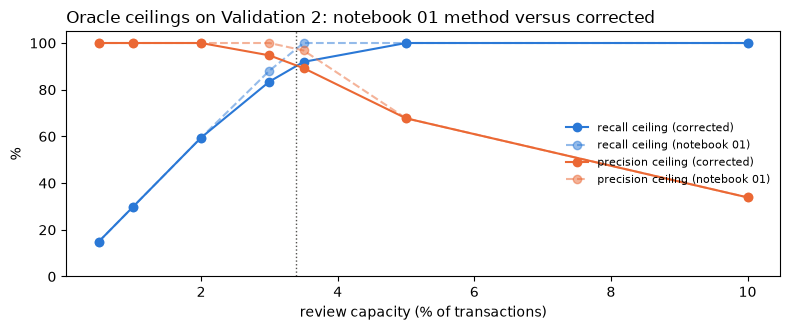

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.4))
x = 100 * np.array(CAPS)
ax.plot(x, 100 * oracle["recall ceiling (corrected)"], marker="o", color="#2a78d6", label="recall ceiling (corrected)")
ax.plot(x, 100 * oracle["recall ceiling (nb01 method)"], marker="o", ls="--", color="#2a78d6", alpha=0.5, label="recall ceiling (notebook 01)")
ax.plot(x, 100 * oracle["precision ceiling (corrected)"], marker="o", color="#eb6834", label="precision ceiling (corrected)")
ax.plot(x, 100 * oracle["precision ceiling (nb01 method)"], marker="o", ls="--", color="#eb6834", alpha=0.5, label="precision ceiling (notebook 01)")
ax.axvline(100 * pi_v2, color="#52514e", ls=":", lw=1)
ax.set_xlabel("review capacity (% of transactions)"); ax.set_ylabel("%"); ax.set_ylim(0, 105)
ax.set_title("Oracle ceilings on Validation 2: notebook 01 method versus corrected", loc="left")
ax.legend(loc="center right", fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## 5. Population Stability Index (corrects notebook 01 §14.1)

For a feature binned into categories b, with reference shares p_b and comparison shares q_b:

$$
\mathrm{PSI} = \sum_b (q_b - p_b) \ln\frac{q_b}{p_b}
$$

where:

- `b` = a bin (a numeric interval, a categorical level, "other" or "missing");
- `p_b`, `q_b` = shares of the reference and the comparison period in bin b, each floored at 10⁻⁴;
- `Σ_b` = sum over the bins;
- `ln` = natural logarithm.

Conventional reading: below 0.10 small, 0.10–0.25 moderate, 0.25 or above large; these are heuristics, not significance tests. Pairs are written Train→V1, Train→V2 and V1→V2, with V1 = Validation 1 and V2 = Validation 2. The reference period is the earlier period of each pair (Train for Train→V1 and Train→V2; Validation 1 for V1→V2), and the numeric bins and categorical levels come from it.

**Correction.** In notebook 01, the categorical branch replaced every value outside the 20 most frequent levels by `"__other__"` *before* filling missing values, so missing values were counted in `"__other__"` and the stated missing bin did not exist. The corrected method gives missing values their own bin. Numeric columns are unaffected and use the same method in both versions.

In [6]:
def psi_from_counts(ref, cur, eps=1e-4):
    ref = ref / ref.sum(); cur = cur / cur.sum()
    ref, cur = ref.clip(lower=eps), cur.clip(lower=eps)
    return float(((cur - ref) * np.log(cur / ref)).sum())


def bins(col, ref_df, cur_df, corrected, n_bins=10, top_k=20):
    r, c = ref_df[col], cur_df[col]
    if col in CAT_COLS or not pd.api.types.is_numeric_dtype(r):
        top = r.value_counts().index[:top_k]
        if corrected:   # explicit missing bin
            rb = r.astype(object).where(r.isna() | r.isin(top), "__other__").where(r.notna(), "__missing__")
            cb = c.astype(object).where(c.isna() | c.isin(top), "__other__").where(c.notna(), "__missing__")
        else:           # notebook 01: missing values fall into "__other__"
            rb = r.where(r.isin(top), "__other__").fillna("__missing__")
            cb = c.where(c.isin(top), "__other__").fillna("__missing__")
    else:               # numeric: identical in both versions (notebook 01 method)
        edges = np.unique(np.nanquantile(r, np.linspace(0, 1, n_bins + 1)))
        if len(edges) < 3:
            rb, cb = r.fillna(-9e9).astype(str), c.fillna(-9e9).astype(str)
        else:
            edges[0], edges[-1] = -np.inf, np.inf
            rb = pd.cut(r, edges, include_lowest=True).astype(str).where(r.notna(), "__missing__")
            cb = pd.cut(c, edges, include_lowest=True).astype(str).where(c.notna(), "__missing__")
    return rb, cb


def psi(col, ref_df, cur_df, corrected):
    rb, cb = bins(col, ref_df, cur_df, corrected)
    levels = sorted(set(rb) | set(cb), key=str)
    return psi_from_counts(rb.value_counts().reindex(levels, fill_value=0).astype(float),
                           cb.value_counts().reindex(levels, fill_value=0).astype(float))


PAIRS = {"Train->V1": (train, v1), "Train->V2": (train, v2), "V1->V2": (v1, v2)}
records = []
for col in FEAT_COLS:
    row = {"feature": col, "type": "categorical" if col in CAT_COLS else "numeric"}
    for name, (ref_df, cur_df) in PAIRS.items():
        row[f"{name} (nb01)"] = psi(col, ref_df, cur_df, corrected=False)
        row[f"{name} (corrected)"] = (row[f"{name} (nb01)"] if col not in CAT_COLS
                                      else psi(col, ref_df, cur_df, corrected=True))
    records.append(row)
psi_df = pd.DataFrame(records).set_index("feature")
print(f"PSI computed for {len(psi_df)} features x {len(PAIRS)} period pairs")

PSI computed for 431 features x 3 period pairs


### 5.1 Replication check against the saved notebook 01 values

The notebook 01 method must reproduce the saved band counts (Train→V2: 396 small, 23 moderate, 12 large) and the saved values of nine features from its top-15 table.

In [7]:
BANDS = [-np.inf, 0.10, 0.25, np.inf]
LABELS = ["<0.10", "0.10-0.25", ">=0.25"]
band = lambda s: pd.cut(s, BANDS, right=False, labels=LABELS)

NB01_BANDS_T2V2 = {"<0.10": 396, "0.10-0.25": 23, ">=0.25": 12}
NB01_TOP = {   # notebook 01 §14.1: Train->V1, Train->V2, V1->V2
    "id_31": (0.649, 0.701, 0.058), "id_13": (0.531, 0.663, 0.285), "M3": (0.317, 0.376, 0.003),
    "M2": (0.317, 0.375, 0.003), "M1": (0.316, 0.375, 0.003), "M9": (0.419, 0.367, 0.002),
    "M8": (0.418, 0.367, 0.002), "M7": (0.418, 0.367, 0.002), "D11": (0.353, 0.288, 0.015),
}
replicated_bands = band(psi_df["Train->V2 (nb01)"]).value_counts().reindex(LABELS).to_dict()
print("Notebook 01 method, Train->V2 bands:", replicated_bands)
assert replicated_bands == NB01_BANDS_T2V2
for feat, vals in NB01_TOP.items():
    got = tuple(round(psi_df.loc[feat, f"{p} (nb01)"], 3) for p in PAIRS)
    assert np.allclose(got, vals, atol=1e-3), (feat, got, vals)
print("Replication of notebook 01 PSI: OK")

Notebook 01 method, Train->V2 bands: {'<0.10': 396, '0.10-0.25': 23, '>=0.25': 12}
Replication of notebook 01 PSI: OK


### 5.2 Corrected PSI versus notebook 01

In [8]:
cat = psi_df[psi_df["type"] == "categorical"]
summary = []
for p in PAIRS:
    old, new = band(cat[f"{p} (nb01)"]), band(cat[f"{p} (corrected)"])
    summary.append({"pair": p,
                    "categorical features with changed PSI (|diff| > 0.001)": int(((cat[f"{p} (corrected)"] - cat[f"{p} (nb01)"]).abs() > 1e-3).sum()),
                    "categorical features changing band": int((old != new).sum()),
                    "bands (nb01 method)": band(psi_df[f"{p} (nb01)"]).value_counts().reindex(LABELS).to_dict(),
                    "bands (corrected)": band(psi_df[f"{p} (corrected)"]).value_counts().reindex(LABELS).to_dict()})
display(pd.DataFrame(summary).set_index("pair"))

changed = []
for p in PAIRS:
    d = cat[[f"{p} (nb01)", f"{p} (corrected)"]].copy()
    d.columns = ["nb01", "corrected"]
    d = d[(d["corrected"] - d["nb01"]).abs() > 1e-3]
    d["pair"] = p
    d["band (nb01)"], d["band (corrected)"] = band(d["nb01"]), band(d["corrected"])
    changed.append(d)
changed = pd.concat(changed).reset_index().sort_values(["pair", "corrected"], ascending=[True, False])
print("Categorical features whose PSI changes:")
changed.round(3)

,categorical features with changed PSI (|diff| > 0.001),categorical features changing band,bands (nb01 method),bands (corrected)
pair,,,,
Train->V1,8,0,"{'<0.10': 373, '0.10-0.25': 38, '>=0.25': 20}","{'<0.10': 373, '0.10-0.25': 38, '>=0.25': 20}"
Train->V2,8,0,"{'<0.10': 396, '0.10-0.25': 23, '>=0.25': 12}","{'<0.10': 396, '0.10-0.25': 23, '>=0.25': 12}"
V1->V2,5,0,"{'<0.10': 428, '0.10-0.25': 2, '>=0.25': 1}","{'<0.10': 428, '0.10-0.25': 2, '>=0.25': 1}"


Categorical features whose PSI changes:


,feature,nb01,corrected,pair,band (nb01),band (corrected)
4,id_13,0.531,0.845,Train->V1,>=0.25,>=0.25
6,id_31,0.649,0.744,Train->V1,>=0.25,>=0.25
5,id_19,0.068,0.078,Train->V1,<0.10,<0.10
7,id_33,0.072,0.075,Train->V1,<0.10,<0.10
0,card2,0.022,0.029,Train->V1,<0.10,<0.10
1,card3,0.010,0.016,Train->V1,<0.10,<0.10
3,P_emaildomain,0.010,0.011,Train->V1,<0.10,<0.10
2,addr1,0.004,0.010,Train->V1,<0.10,<0.10
12,id_13,0.663,1.035,Train->V2,>=0.25,>=0.25
15,id_31,0.701,0.786,Train->V2,>=0.25,>=0.25


In [9]:
print("Top 15 features by corrected PSI, Train->V2:")
psi_df.sort_values("Train->V2 (corrected)", ascending=False).head(15)[
    ["type"] + [f"{p} (corrected)" for p in PAIRS]].round(3)

Top 15 features by corrected PSI, Train->V2:


,type,Train->V1 (corrected),Train->V2 (corrected),V1->V2 (corrected)
feature,,,,
id_13,categorical,0.845,1.035,0.285
id_31,categorical,0.744,0.786,0.059
M3,categorical,0.317,0.376,0.003
M2,categorical,0.317,0.375,0.003
M1,categorical,0.316,0.375,0.003
M9,categorical,0.419,0.367,0.002
M8,categorical,0.418,0.367,0.002
M7,categorical,0.418,0.367,0.002
D11,numeric,0.353,0.288,0.015


## 6. Missingness blocks of `V1`–`V339` (corrects notebook 01 §8)

Notebook 01 grouped the `V` columns by their **number** of missing Train rows and reported 14 groups. Equal counts do not show that the columns are missing on the **same** rows. Here each column's missing-row pattern on Train rows is hashed, and the count-based groups are compared with the groups of identical patterns. The number of numeric inputs with at least one missing Train value is also recounted, because it sets the number of missingness indicators in [DR-012](../docs/decisions/DR-012-neural-network-input-representation.md).

In [10]:
VCOLS = [c for c in NUM_COLS if c.startswith("V") and c[1:].isdigit()]
assert len(VCOLS) == 339
miss = train[VCOLS].isna()
counts = miss.sum()
patterns = pd.Series({c: hashlib.sha256(np.packbits(miss[c].to_numpy()).tobytes()).hexdigest() for c in VCOLS})

by_count = counts.groupby(counts).apply(lambda s: list(s.index))
block_rows = []
for n_missing, cols in by_count.items():
    block_rows.append({"missing Train rows": int(n_missing), "columns": len(cols),
                       "distinct missing-row patterns": patterns[cols].nunique(),
                       "first column": cols[0], "last column": cols[-1]})
blocks = pd.DataFrame(block_rows).sort_values("missing Train rows").reset_index(drop=True)

num_with_missing = [c for c in NUM_COLS if train[c].isna().any()]
print(f"Groups by missing count: {len(by_count)}; groups by identical missing-row pattern: {patterns.nunique()}")
print(f"Count-based groups whose columns all share one pattern: {(blocks['distinct missing-row patterns'] == 1).sum()} of {len(blocks)}")
print(f"Numeric inputs with at least one missing Train value: {len(num_with_missing)} "
      f"({sum(c in VCOLS for c in num_with_missing)} V columns, {sum(c not in VCOLS for c in num_with_missing)} others)")
blocks

Groups by missing count: 14; groups by identical missing-row pattern: 14
Count-based groups whose columns all share one pattern: 14 of 14
Numeric inputs with at least one missing Train value: 324 (296 V columns, 28 others)


,missing Train rows,columns,distinct missing-row patterns,first column,last column
0,0,43,1,V95,V137
1,12,32,1,V279,V321
2,273,11,1,V281,V315
3,58354,23,1,V12,V34
4,59389,22,1,V53,V74
5,65547,20,1,V75,V94
6,114465,18,1,V35,V52
7,211816,11,1,V1,V11
8,270364,16,1,V220,V272
9,271871,19,1,V169,V210


## 7. Findings

- **[D] Raw headers (notebook 02 §2.2).** The header lines contain 394 (`train_transaction.csv`) and 41 (`train_identity.csv`) names, with no repeated name. Notebook 02's conclusion stands; it is now established by a check that can fail.
- **[D] Oracle ceilings (notebook 01 §6).** The notebook 01 method reproduces the saved notebook 01 values within their saved rounding. For the scenarios used by the design, the corrected recall ceilings are unchanged (0.297 at 1 %, 0.595 at 2 %, 1.000 at 5 % and 10 %) and the corrected precision ceilings agree to the displayed precision (1.000, 1.000, 0.678, 0.339); the maximum lift differs only through the rounding of K (19.995 instead of 20.000 at 5 %; 9.998 instead of 10.000 at 10 %). The ceilings differ materially only for the exploratory scenarios in which capacity binds on some days: 3 % recall 0.835 (notebook 01: 0.881) and precision 0.947 (1.000); 3.5 % recall 0.919 (1.000) and precision 0.892 (0.968).
- **[D] Population Stability Index (notebook 01 §14.1).** The notebook 01 method reproduces the saved band counts (Train→V2: 396 small, 23 moderate, 12 large) and the saved values of nine top-ranked features. With a separate missing bin, the PSI changes by more than 0.001 for 8 (Train→V1), 8 (Train→V2) and 5 (V1→V2) categorical features, 12 distinct features in total, most for `id_13` (Train→V2 0.663 → 1.035) and `id_31` (0.701 → 0.786); no feature changes band in any period pair, so every band count is unchanged.
- **[D] `V` missingness blocks (notebook 01 §8).** The 14 groups formed by the number of missing Train rows coincide with 14 identical missing-row patterns: every count-based group is a true block. 324 numeric inputs have at least one missing Train value (296 `V` columns and 28 others), not about 290 as previously stated; the 32 columns of feature-catalog block 12 have 12 missing Train rows, which the earlier count had treated as complete.
- **[I] Consequences.** No value used by the protocol's hypotheses, capacity scenarios or statistical plan changes, and the drift conclusions that cite PSI qualitatively (DR-001, DR-003) stand. The neural-network input count of [DR-012](../docs/decisions/DR-012-neural-network-input-representation.md) becomes 431 + 324 = 755 inputs (756 tokens for FT-Transformer, the Feature Tokenizer + Transformer model), still within the 800 tokens covered by the graphics processing unit (GPU) memory probe of Issue #50.

## Symbols and notation

| Symbol / abbreviation | Meaning |
|---|---|
| [D], [I] | Evidence tags: observed dataset evidence; inference or recommendation |
| b | A bin of a feature in the PSI calculation |
| c | Review-capacity share (share of transactions that can be reviewed) |
| D | Number of days in the Validation 2 (V2) period (D = 28) |
| d | A relative day |
| DR-NNN | Decision Record NNN in `docs/decisions/` |
| F_d | Number of frauds on day d |
| FT-Transformer | Feature Tokenizer + Transformer (a neural model for tabular data) |
| GPU | Graphics processing unit |
| `isFraud` | Target: 1 = fraud, 0 = legitimate |
| K | Fixed daily review budget (reviews per relative day) |
| ln | Natural logarithm |
| p_b, q_b | Shares of the reference and the comparison period in bin b |
| π_V2 | Fraud prevalence in Validation 2 |
| PSI | Population Stability Index (a measure of distribution shift) |
| Relative day | `TransactionDT` divided by 86,400 seconds, rounded down; no calendar date inferred |
| Σ_b, Σ_d | Sum over the bins; sum over the days of the V2 period |
| SHA-256 | Secure Hash Algorithm, 256-bit (file checksum; also used here to hash missing-row patterns) |
| Test | Relative days 155–182; labels sealed |
| Train, V1, V2 | Relative days 1–105; 106–126 (Validation 1); 127–154 (Validation 2) |
| `TransactionDT` | Time offset in seconds from an undisclosed reference point |
| `TransactionID` | Row identifier and join key |
| `V1`–`V339` | Organiser-engineered numeric feature columns (distinct from the Validation 1/2 partitions) |